In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update(
    {
        "font.size": 10,
        "axes.titlesize": 14,
        "axes.labelsize": 10,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "legend.fontsize": 10,
        # embed TrueType fonts in PDF for consistent rendering
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        # use Computer Modern (mathtext + serif fallback)
        "font.family": "serif",
        "font.serif": ["Computer Modern", "DejaVu Serif"],
        "mathtext.fontset": "cm",
        # avoid requiring an external TeX installation by using mathtext
        "text.usetex": False,
    }
)

In [2]:
import os

import jax
import jax.numpy as jnp

os.environ["CUDA_VISIBLE_DEVICES"] = "3"

HORIZON = 10
INITIAL_STATE = jnp.array([3.0, 5.0])  # position, velocity

In [3]:
from hcnn.system_constraints import SystemConstraintsBall
from hcnn.training.train_bundle import TrainBundle

system = TrainBundle.build_double_integrator()

sys_constraints = SystemConstraintsBall.factory(
    center=jnp.array([6.5, 0]), radius=1.5, action_dim=1
)

In [4]:
gain_matrix = jnp.array([[0.2, 2 / 3]])

In [5]:
from hcnn.optimization_layer import Rollout


def scan_fn(state, _):
    action = -gain_matrix @ state
    next_state = system.sys_dynamics(state, action)
    return next_state, (state, action)


states, actions = jax.lax.scan(scan_fn, INITIAL_STATE, None, length=HORIZON)[1]

raw_rollout = Rollout(states, actions)

In [6]:
raw_rollout

Rollout(states=Array([[ 3.        ,  5.        ],
       [ 6.0333333 ,  1.0666666 ],
       [ 6.141111  , -0.8511112 ],
       [ 4.959593  , -1.5119259 ],
       [ 3.455683  , -1.4958938 ],
       [ 2.112852  , -1.1897678 ],
       [ 1.1083883 , -0.81915975],
       [ 0.451443  , -0.4947309 ],
       [ 0.07647809, -0.2551989 ],
       [-0.10130231, -0.10036191]], dtype=float32), actions=Array([[-3.9333334 ],
       [-1.9177778 ],
       [-0.66081476],
       [ 0.0160321 ],
       [ 0.306126  ],
       [ 0.37060812],
       [ 0.32442886],
       [ 0.239532  ],
       [ 0.15483698],
       [ 0.0871684 ]], dtype=float32))

In [7]:
from hcnn.optimization_layer import ProjectionPhi, ProjectionProblem
from hcnn.solver import SQPParameters

projection_problem = ProjectionProblem.factory(
    sys_dynamics=system.sys_dynamics,
    sys_constraints=sys_constraints,
    horizon=HORIZON,
    projection_relaxation_penalty=1e3,
)
phi = ProjectionPhi(
    states_ref=raw_rollout.states,
    actions_ref=raw_rollout.actions,
    initial_state=INITIAL_STATE,
)
sqp_problem = projection_problem.replace(phi=phi)
sqp_parameters = SQPParameters(
    tol_prim=1e-5,
    tol_dual=1e-5,
    tol_osqp=1e-6,
    rho_equality_mult=1,
    max_iter_lin=5000,
    max_iter_nonlin=10,
    epsilon=1e-12,
)

In [8]:
# Manual SQP iterations to log residuals
from functools import partial

import jax.numpy as jnp

from hcnn.solver.solver_sqp import SQPVariables, sqp_step

# Initialize SQP variables
variables = SQPVariables.factory(problem=sqp_problem, parameters=sqp_parameters)

# Lists to store residuals
primal_residuals = []
dual_residuals = []

step_jit = jax.jit(
    partial(sqp_step, problem=sqp_problem, parameters=sqp_parameters)
)

for i in range(sqp_parameters.max_iter_nonlin):
    print(f"Iteration {i + 1}")
    variables = step_jit(variables)
    primal_residuals.append(variables.max_primal_residual)
    dual_residuals.append(variables.max_dual_residual)

# Convert lists to JAX arrays for plotting
primal_residuals = jnp.stack(primal_residuals)
dual_residuals = jnp.stack(dual_residuals)

# Extract final solution
x_star_manual = variables.x
optvar = projection_problem.x_to_optvar(x_star_manual)
proj_rollout = Rollout(
    states=optvar.states,
    actions=optvar.actions,
)

Iteration 1
Iteration 2
Iteration 3
Iteration 4
Iteration 5
Iteration 6
Iteration 7
Iteration 8
Iteration 9
Iteration 10


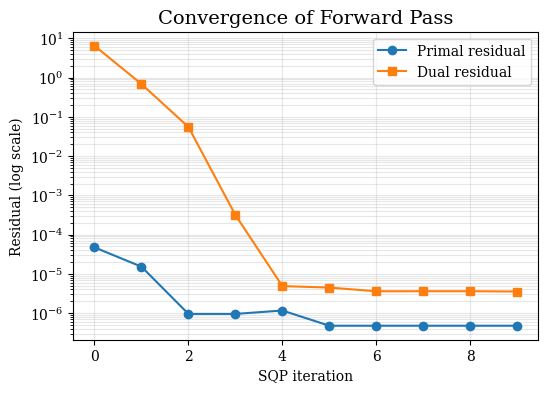

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(primal_residuals, label="Primal residual", marker="o")
ax.plot(dual_residuals, label="Dual residual", marker="s")
ax.set_yscale("log")
ax.set_xlabel("SQP iteration")
ax.set_ylabel("Residual (log scale)")
ax.set_title("Convergence of Forward Pass")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.show()
fig.savefig("convergence_non_convex.pdf")

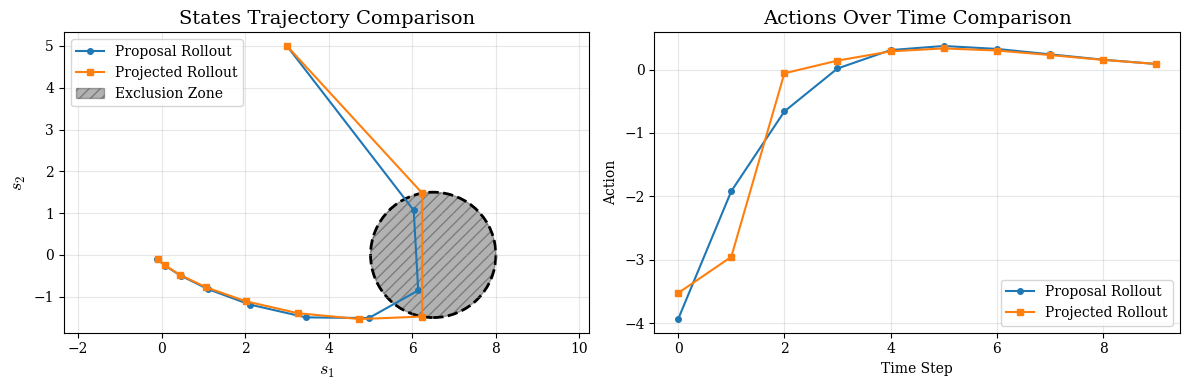

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


In [10]:
from matplotlib import pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Plot states comparison
ax1.plot(
    raw_rollout.states[:, 0],
    raw_rollout.states[:, 1],
    "o-",
    label="Proposal Rollout",
    markersize=4,
    linewidth=1.5,
)
ax1.plot(
    proj_rollout.states[:, 0],
    proj_rollout.states[:, 1],
    "s-",
    label="Projected Rollout",
    markersize=4,
    linewidth=1.5,
)

# Plot the ball constraint (exclusion zone)
circle = plt.Circle(
    (sys_constraints.center[0], sys_constraints.center[1]),
    sys_constraints.radius,
    color="k",
    fill=True,
    alpha=0.3,
    label="Exclusion Zone",
    hatch="///",
)
ax1.add_patch(circle)

# Also add the boundary circle
circle_boundary = plt.Circle(
    (sys_constraints.center[0], sys_constraints.center[1]),
    sys_constraints.radius,
    color="k",
    fill=False,
    linewidth=2,
    linestyle="--",
)
ax1.add_patch(circle_boundary)

ax1.set_xlabel(r"$s_1$", fontsize=13)
ax1.set_ylabel(r"$s_2$", fontsize=13)
ax1.set_title("States Trajectory Comparison")
ax1.legend(loc="upper left")
ax1.axis("equal")
ax1.grid(True, alpha=0.3)

# Plot actions comparison
time_steps = range(len(raw_rollout.actions))
ax2.plot(
    time_steps,
    raw_rollout.actions[:, 0],
    "o-",
    label="Proposal Rollout",
    markersize=4,
    linewidth=1.5,
)
ax2.plot(
    time_steps,
    proj_rollout.actions[:, 0],
    "s-",
    label="Projected Rollout",
    markersize=4,
    linewidth=1.5,
)
ax2.set_xlabel("Time Step")
ax2.set_ylabel("Action")
ax2.set_title("Actions Over Time Comparison")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
fig.savefig("trajectory_non_convex.pdf")

In [11]:
x_star = variables.x
y_star = variables.y
q_plus_s = variables.q_plus_s
problem = sqp_problem
parameters = sqp_parameters

In [12]:
tangent = jax.tree_util.tree_map(
    lambda x: jax.random.normal(jax.random.key(0), x.shape), phi
)
cotangent = jax.tree_util.tree_map(
    lambda x: jax.random.normal(jax.random.key(1), x.shape), x_star
)

In [13]:
# Calculate numerical JVP for gradient verification
# This implements the same numerical differentiation as JAX's check_vjp

eps = 3 * parameters.tol_prim  # finite difference step size


def numerical_jvp(f, primals, tangents, eps=eps):
    """Compute JVP using finite differences: [f(x + ε·v) - f(x - ε·v)] / (2ε)"""

    # Scale tangents by eps
    def scalar_mul(tree, scalar):
        return jax.tree_util.tree_map(lambda x: x * scalar, tree)

    def tree_add(tree1, tree2):
        return jax.tree_util.tree_map(lambda x, y: x + y, tree1, tree2)

    def tree_sub(tree1, tree2):
        return jax.tree_util.tree_map(lambda x, y: x - y, tree1, tree2)

    delta = scalar_mul(tangents, eps)
    f_pos = f(tree_add(primals, delta))
    f_neg = f(tree_sub(primals, delta))
    return scalar_mul(tree_sub(f_pos, f_neg), 0.5 / eps)


# Define the function we want to differentiate
# This should be the projection function from phi to x_star
def projection_fn(phi_input):
    """Function that takes phi and returns the optimized x"""
    # Create a new projection problem with the input phi
    temp_problem = projection_problem.replace(phi=phi_input)

    # Initialize SQP variables for this problem
    temp_variables = SQPVariables.factory(
        problem=temp_problem, parameters=sqp_parameters
    )

    # Run SQP optimization
    step_fn = jax.jit(
        partial(sqp_step, problem=temp_problem, parameters=sqp_parameters)
    )

    for _ in range(sqp_parameters.max_iter_nonlin):
        temp_variables = step_fn(temp_variables)

    return temp_variables.x


# Calculate numerical JVP
tangent_out = numerical_jvp(projection_fn, phi, tangent, eps=eps)

In [14]:
v1 = cotangent

## Precompute JVP, VJP and HVP for the constraint function
# h_jvp computes v -> dh/dx @ v
h, h_jvp = jax.linearize(problem.constraint_fn, x_star)
# h_vjp computes w -> w^T @ dh/dx
_, h_vjp = jax.vjp(problem.constraint_fn, x_star)

## Implicit VJP (step 1)
reg = 10 * parameters.tol_prim
y_plus = jnp.maximum(y_star, 0.0)
y_minus = jnp.maximum(-y_star, 0.0)

frac_upper = y_plus / (reg + problem.upper_bound - h)
frac_lower = y_minus / (reg + h - problem.lower_bound)
frac_sum = frac_upper + frac_lower


def schur_lhs(u1: jax.Array) -> jax.Array:
    return q_plus_s * u1 + h_vjp(frac_sum * h_jvp(u1))[0] + 1e-4 * u1


u1, _ = jax.scipy.sparse.linalg.bicgstab(A=schur_lhs, b=-v1)

jvp_u1 = h_jvp(u1)
u2 = jvp_u1 / (reg + problem.upper_bound - h)
u3 = jvp_u1 / (problem.lower_bound - reg - h)

## Explicit VJP (step 2)
## phi
g_phi_d_1 = jax.grad(
    lambda phi_arg: jnp.dot(
        jax.jvp(
            lambda x_inner: problem.constraint_fn_phi(x_inner, phi_arg),
            (x_star,),
            (u1,),
        )[1],
        y_star,
    ),
)(problem.phi)

g_phi_d_2 = jax.vjp(
    lambda phi_arg: problem.constraint_fn_phi(x_star, phi_arg),
    problem.phi,
)[1](u2 * y_plus - u3 * y_minus)[0]
cotangent_out = jax.tree_util.tree_map(jnp.add, g_phi_d_1, g_phi_d_2)

jnp.mean(schur_lhs(u1) / -v1)

Array(1.0458653, dtype=float32)

In [15]:
def inner_prod(xs, ys):
    """Compute inner product between two pytrees"""

    def contract(x, y):
        return jnp.real(jnp.dot(jnp.conj(x).reshape(-1), y.reshape(-1)))

    return jax.tree_util.tree_reduce(
        jnp.add, jax.tree_util.tree_map(contract, xs, ys)
    )


# The key mathematical relationship we're verifying:
# ⟨tangent, VJP(cotangent)⟩ = ⟨JVP(tangent), cotangent⟩

ip = inner_prod(tangent, cotangent_out)
ip_expected = inner_prod(tangent_out, cotangent)

print(f"Inner product (tangent, VJP(cotangent)): {ip:.6f}")
print(f"Inner product (JVP(tangent), cotangent): {ip_expected:.6f}")
print(f"Difference: {jnp.abs(ip - ip_expected):.6e}")

Inner product (tangent, VJP(cotangent)): 29.179184
Inner product (JVP(tangent), cotangent): 29.612453
Difference: 4.332695e-01


In [16]:
# Analysis of BiCGSTAB convergence in backward pass
# Track ⟨tangent, VJP(cotangent)⟩ = ⟨JVP(tangent), cotangent⟩ for different bicgstab iterations
bicgstab_iterations = jnp.arange(0, 210, 10)

inner_products_vjp = []
inner_products_jvp = []
differences = []

# Store the expected value (from numerical JVP) for comparison
ip_numerical = inner_prod(tangent_out, cotangent)

for max_iter in bicgstab_iterations:
    # Solve the Schur complement system with limited iterations
    u1_iter, info = jax.scipy.sparse.linalg.bicgstab(
        A=schur_lhs,
        b=-v1,
        maxiter=int(max_iter),
    )

    jvp_u1_iter = h_jvp(u1_iter)
    u2_iter = jvp_u1_iter / (reg + problem.upper_bound - h)
    u3_iter = jvp_u1_iter / (problem.lower_bound - reg - h)

    # Compute VJP result with this u1
    g_phi_d_1_iter = jax.grad(
        lambda phi_arg: jnp.dot(
            jax.jvp(
                lambda x_inner: problem.constraint_fn_phi(x_inner, phi_arg),
                (x_star,),
                (u1_iter,),
            )[1],
            y_star,
        ),
    )(problem.phi)

    g_phi_d_2_iter = jax.vjp(
        lambda phi_arg: problem.constraint_fn_phi(x_star, phi_arg),
        problem.phi,
    )[1](u2_iter * y_plus - u3_iter * y_minus)[0]

    cotangent_out_iter = jax.tree_util.tree_map(
        jnp.add, g_phi_d_1_iter, g_phi_d_2_iter
    )

    # Calculate inner products
    ip_vjp = inner_prod(tangent, cotangent_out_iter)
    ip_jvp = (
        ip_numerical  # This stays constant (from numerical differentiation)
    )
    diff = jnp.abs(ip_vjp - ip_jvp)

    inner_products_vjp.append(ip_vjp)
    inner_products_jvp.append(ip_jvp)
    differences.append(diff)

    print(
        f"Iter {max_iter:2d}: VJP={ip_vjp:.6f}, JVP={ip_jvp:.6f}, Diff={diff:.6e}"
    )

# Convert to JAX arrays for plotting
inner_products_vjp = jnp.array(inner_products_vjp)
inner_products_jvp = jnp.array(inner_products_jvp)
differences = jnp.array(differences)

print(f"Difference: {differences[-1]:.6e}")

Iter  0: VJP=0.000000, JVP=29.612453, Diff=2.961245e+01
Iter 10: VJP=15.204815, JVP=29.612453, Diff=1.440764e+01
Iter 20: VJP=24.335367, JVP=29.612453, Diff=5.277086e+00
Iter 30: VJP=45.576385, JVP=29.612453, Diff=1.596393e+01
Iter 40: VJP=55.577892, JVP=29.612453, Diff=2.596544e+01
Iter 50: VJP=60.684166, JVP=29.612453, Diff=3.107171e+01
Iter 60: VJP=60.258972, JVP=29.612453, Diff=3.064652e+01
Iter 70: VJP=46.895729, JVP=29.612453, Diff=1.728328e+01
Iter 80: VJP=36.932335, JVP=29.612453, Diff=7.319881e+00
Iter 90: VJP=34.645332, JVP=29.612453, Diff=5.032879e+00
Iter 100: VJP=31.912449, JVP=29.612453, Diff=2.299995e+00
Iter 110: VJP=30.321564, JVP=29.612453, Diff=7.091103e-01
Iter 120: VJP=29.265667, JVP=29.612453, Diff=3.467865e-01
Iter 130: VJP=28.711388, JVP=29.612453, Diff=9.010658e-01
Iter 140: VJP=28.478004, JVP=29.612453, Diff=1.134449e+00
Iter 150: VJP=28.097527, JVP=29.612453, Diff=1.514927e+00
Iter 160: VJP=28.055004, JVP=29.612453, Diff=1.557449e+00
Iter 170: VJP=27.835495, 

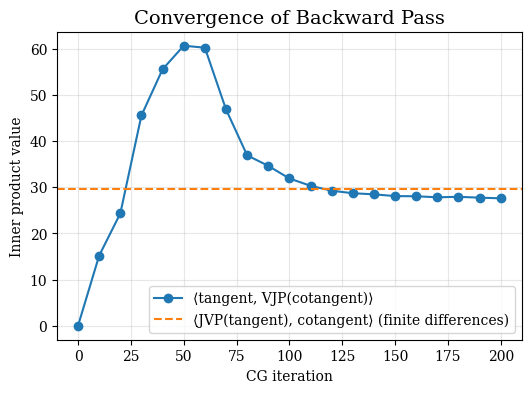

In [21]:
# Plot convergence in backward pass
fig, ax = plt.subplots(figsize=(6, 4))

# Inner products comparison
ax.plot(
    bicgstab_iterations,
    inner_products_vjp,
    "o-",
    color="C0",
    label=r"⟨tangent, VJP(cotangent)⟩",
)
ax.axhline(
    y=ip_numerical,
    color="C1",
    linestyle="--",
    label=r"⟨JVP(tangent), cotangent⟩ (finite differences)",
)
ax.set_xlabel("CG iteration")
ax.set_ylabel("Inner product value")
ax.set_title("Convergence of Backward Pass")
ax.legend()
ax.grid(True, alpha=0.3)


plt.show()
fig.savefig("convergence_non_convex_bwd.pdf")
